<a href="https://colab.research.google.com/github/cdube89128/DATA_620/blob/main/Week8_High_Frequency_Words.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 8 Homework - High Frequency Words
### DATA 620
### Catherine Dube

**HW Prompt**

This week's assignment is to answer these questions in an IPython Notebook, posted to GitHub:

1. Choose a corpus of interest.
2. How many total unique words are in the corpus? (Please feel free to define unique words in any interesting, defensible way).
3. Taking the most common words, how many unique words represent half of the total words in the corpus?
4. Identify the 200 highest frequency words in this corpus.
5. Create a graph that shows the relative frequency of these 200 words.
6. Does the observed relative frequency of these words follow Zipf's law? Explain.
7. In what ways do you think the frequency of the words in this corpus differ from "all words in all corpora."

**My HW Recap**

* My corpus is *Frankenstein* by Mary Shelley. I recall liking the book, it's fun leading up to Halloween season, and it's public domain so it's easy to obtain the text.
* I read the book  from [Project Gutenberg](https://www.gutenberg.org/ebooks/84).
* To answer the last question, I compare Frankenstein against the Brown Corpus, which the textbook uses as its general sample of English across many kinds of writing.
* What I expect going in: the word counts should follow Zipf's law, since that's supposed to hold for most text. And since the novel is told through letters and first-person accounts, I expect words like "I" and "my" to rank higher than usual.
* I answer each question in its own section as I go, and my answers to all seven are summed up at the very bottom.

In [ ]:
import re
import textwrap
import urllib.request
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from nltk.corpus import brown, stopwords

# NLTK data used below: tokenizer, Brown Corpus, stopword list, lemmatizer, part-of-speech tagger
for package in [
    "punkt",
    "punkt_tab",
    "brown",
    "stopwords",
    "wordnet",
    "averaged_perceptron_tagger",
    "averaged_perceptron_tagger_eng",
]:
  nltk.download(package, quiet=True)

## Question 1: Choosing and Loading the Corpus

In [ ]:
# Read Frankenstein from Project Gutenberg
url = "https://www.gutenberg.org/cache/epub/84/pg84.txt"

req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
raw = urllib.request.urlopen(req).read().decode("utf-8-sig")

print(f"Source: {url}")
print(f"Raw text: {len(raw):,} characters")
print(raw[:300])

Source: https://www.gutenberg.org/cache/epub/84/pg84.txt
Raw text: 446,582 characters
The Project Gutenberg eBook of Frankenstein; or, The modern Prometheus
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of th


In [ ]:
# Strip the Project Gutenberg header and footer, and clean up the text so only the novel is left
start_marker = raw.find("*** START OF")
end_marker = raw.find("*** END OF")

if start_marker != -1 and end_marker != -1:
  text = raw[raw.find("\n", start_marker) + 1:end_marker]
else:
  print("Gutenberg markers not found, keeping the full text.")
  text = raw

# Skip the title page and table of contents: the story starts at the second "Letter 1"
story_start = text.find("Letter 1", text.find("Letter 1") + 1)
if story_start != -1:
  text = text[story_start:]

# Drop the "Letter 1" / "Chapter 1" heading lines so they aren't counted as words
text = re.sub(r"^\s*(Letter|Chapter) \d+\s*$", "", text, flags=re.MULTILINE)

# Swap curly apostrophes for straight ones, so the tokenizer keeps "Elizabeth's" together
text = text.replace("\u2019", "'").replace("\u2018", "'")

print(f"Novel text: {len(text):,} characters")
print("\n--- Start ---")
print(text[:400])
print("\n--- End ---")
print(text[-300:])

Novel text: 425,630 characters

--- Start ---

_To Mrs. Saville, England._


St. Petersburgh, Dec. 11th, 17—.


You will rejoice to hear that no disaster has accompanied the
commencement of an enterprise which you have regarded with such evil
forebodings. I arrived here yesterday, and my first task is to assure
my dear sister of my welfare and increasing confidence in the success
of my undertaking.

I am already far north of Londo

--- End ---
to the sea by the winds. My spirit
will sleep in peace, or if it thinks, it will not surely think thus.
Farewell.”

He sprang from the cabin-window as he said this, upon the ice raft
which lay close to the vessel. He was soon borne away by the waves and
lost in darkness and distance.







In [ ]:
# Break the text into tokens (words and punctuation)
tokens = nltk.word_tokenize(text)

print(f"{len(tokens):,} tokens")
print(tokens[:40])

85,079 tokens
['_To', 'Mrs.', 'Saville', ',', 'England._', 'St.', 'Petersburgh', ',', 'Dec.', '11th', ',', '17—', '.', 'You', 'will', 'rejoice', 'to', 'hear', 'that', 'no', 'disaster', 'has', 'accompanied', 'the', 'commencement', 'of', 'an', 'enterprise', 'which', 'you', 'have', 'regarded', 'with', 'such', 'evil', 'forebodings', '.', 'I', 'arrived', 'here']


**Loading Summary**

* Once the Project Gutenberg header, footer, title page and table of contents are stripped off, what's left is just the novel
  * The raw download is ~447K characters, and the novel itself is ~426K. The text now starts with Walton's first letter ("To Mrs. Saville, England") and ends with the creature disappearing "in darkness and distance."
* Tokenizing breaks the novel into ~85K tokens
  * Tokens include punctuation and numbers as well as words, so the next step is deciding which of these actually count as words.

## Question 2: How Many Unique Words Are There?

The answer depends on what counts as a "word," so here I'm doing something similar to what the text book did for *Moby Dick*. I start with raw tokens, then I ignore capitalization, then I keep only alphabetic words. As a last step I also lemmatize, so that words like "creature" and "creatures" count as one word.

In [ ]:
# Count unique words under stricter and stricter definitions
lowered = [t.lower() for t in tokens]
words = [t for t in lowered if t.isalpha()]

lemmatizer = nltk.WordNetLemmatizer()
lemmas = [lemmatizer.lemmatize(w) for w in words]

definitions = pd.DataFrame(
    [
        ("1. Raw tokens", len(tokens), len(set(tokens))),
        ("2. Lowercased", len(lowered), len(set(lowered))),
        ("3. Lowercased, letters only", len(words), len(set(words))),
        ("4. Lowercased, letters only, lemmatized", len(lemmas), len(set(lemmas))),
    ],
    columns=["definition", "total_words", "unique_words"],
)
print(definitions.to_string(index=False))

                             definition  total_words  unique_words
                          1. Raw tokens        85079          7680
                          2. Lowercased        85079          7335
            3. Lowercased, letters only        74418          6875
4. Lowercased, letters only, lemmatized        74418          6262


**Unique Words Summary**

* I'm using definition 3 (lowercased, letters only). Leaving 6875 unique words.
  * It treats "The" and "the" as the same word and drops punctuation and numbers, which is what most people mean by a word. I didn't use definition 4 and lemmatize for the rest of the questions, this both aligns with the example in the textbook better, but also lemmatizing isn't perfect. Words "dog" and "dogs" might get counted as the same word, but "felt" and "feel" would not. It's an imperfect adjustment that wouldn't change the number of unique words by a large margin if I used it.
* So to recap, with definition 3, Frankenstein has ~6.9K unique words out of ~74K total words
  * Each step shrinks the number of unique words further: ~7.7K unique raw tokens, then ~7.3K once capitalization is ignored, then ~6.9K once punctuation and numbers are gone. Lemmatizing would bring it down to ~6.3K.

## Question 3: How Many Words Make Up Half the Book?

In [ ]:
# How many of the most common words make up half of all the words in the book?
fdist = nltk.FreqDist(words)
total_words = fdist.N()
unique_words = fdist.B()

counts = pd.Series([c for _, c in fdist.most_common()])
cumulative_share = counts.cumsum() / total_words
words_for_half = int((cumulative_share < 0.5).sum()) + 1

print(f"Total words: {total_words:,}")
print(f"Unique words: {unique_words:,}")
print(f"Words used only once: {len(fdist.hapaxes()):,}")
print(
    f"\nThe {words_for_half} most common words"
    f" ({words_for_half / unique_words:.1%} of the vocabulary) make up half of all words."
)

Total words: 74,418
Unique words: 6,875
Words used only once: 2,931

The 60 most common words (0.9% of the vocabulary) make up half of all words.


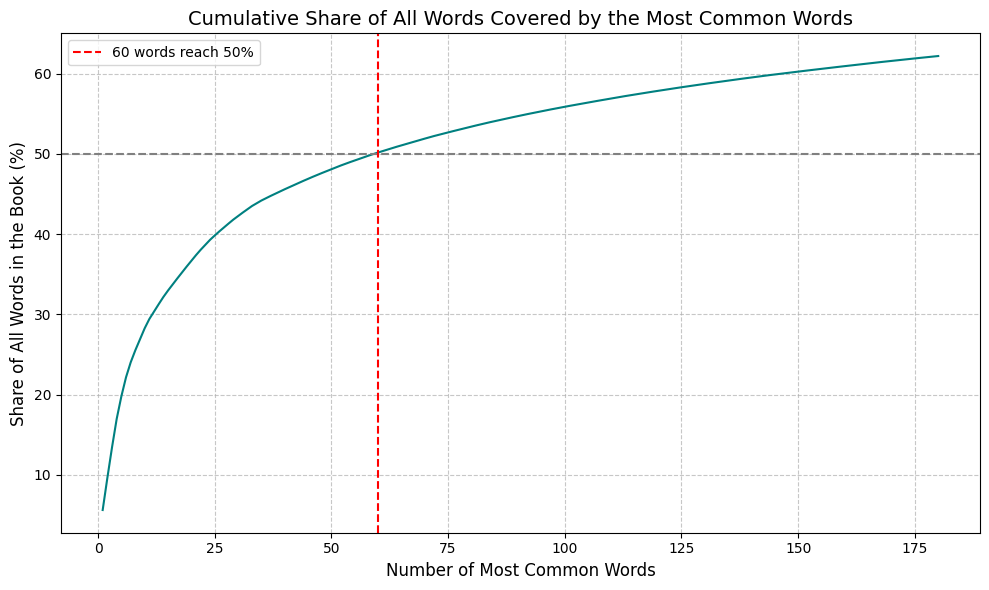

In [ ]:
# Cumulative share of the book covered by the most common words
top_n = max(words_for_half * 3, 100)

plt.figure(figsize=(10, 6))
plt.plot(range(1, top_n + 1), cumulative_share[:top_n] * 100, color="teal")
plt.axhline(50, color="gray", linestyle="--")
plt.axvline(words_for_half, color="red", linestyle="--", label=f"{words_for_half} words reach 50%")
plt.title("Cumulative Share of All Words Covered by the Most Common Words", fontsize=14)
plt.xlabel("Number of Most Common Words", fontsize=12)
plt.ylabel("Share of All Words in the Book (%)", fontsize=12)
plt.legend()
plt.grid(linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

**Half the Book Summary**

* Just 60 words make up half of everything Mary Shelley wrote in this book
  * That's less than 1% of the ~6.9K unique words.  
* This lines up with the text book's Moby Dick example, where ~50 words made up nearly half the book, so a small handful of words doing half the work seems to be normal for English novels.
* At the other end, a huge share of the vocabulary barely shows up at all. ~2.9K words (> 40% of the vocabulary) are used exactly once.

## Question 4: The 200 Most Common Words

In [ ]:
# The 200 highest frequency words, with their counts and relative frequency
top_200 = pd.DataFrame(fdist.most_common(200), columns=["word", "count"])
top_200.insert(0, "rank", range(1, 201))
top_200["relative_frequency"] = top_200["count"] / total_words

print(f"Together, the top 200 words make up {top_200['relative_frequency'].sum():.1%} of the book.\n")
print(textwrap.fill(", ".join(f"{r}. {w}" for r, w in zip(top_200["rank"], top_200["word"])), width=110))
print()
print(top_200.head(25).to_string(index=False))

Together, the top 200 words make up 63.3% of the book.

1. the, 2. and, 3. i, 4. of, 5. to, 6. my, 7. a, 8. in, 9. was, 10. that, 11. me, 12. but, 13. had, 14. with,
15. he, 16. you, 17. which, 18. not, 19. it, 20. his, 21. as, 22. for, 23. on, 24. by, 25. this, 26. from, 27.
her, 28. have, 29. be, 30. when, 31. at, 32. were, 33. is, 34. she, 35. your, 36. him, 37. an, 38. so, 39.
they, 40. one, 41. all, 42. could, 43. will, 44. if, 45. been, 46. their, 47. would, 48. are, 49. or, 50. we,
51. who, 52. no, 53. more, 54. these, 55. now, 56. should, 57. yet, 58. some, 59. before, 60. can, 61. man,
62. myself, 63. father, 64. what, 65. them, 66. am, 67. upon, 68. our, 69. into, 70. its, 71. only, 72. did,
73. do, 74. life, 75. than, 76. every, 77. then, 78. first, 79. might, 80. own, 81. shall, 82. eyes, 83. said,
84. may, 85. time, 86. being, 87. towards, 88. even, 89. saw, 90. how, 91. those, 92. elizabeth, 93. most, 94.
night, 95. found, 96. such, 97. mind, 98. any, 99. day, 100. again,

**Top 200 Summary**

* The top 200 words make up ~63% of the book, and the very top of the list is almost all "plumbing" words
  * Words like "the," "and," "of," "to" and "a" hold the sentences together but don't tell you anything about the story. The first real content word, "man," doesn't show up until rank 61.
* The first-person narration contributes to the top words pretty heavily
  * "I" is the 3rd most common word, "my" is 6th, "me" is 11th and "myself" is 62nd.
  * That makes sense for a book told through Walton's letters, Victor's accounts and the creature's story.
* Further down, but still in the top 200, the story actually shows up a bit with character names and words that communicate the themes in the book.
  * The main characters appear: Elizabeth, Clerval, Justine, Felix, plus "father" and "creature"
  * Heavy emotional words appear: "miserable," "misery," "despair," "horror," "fear," "death," but also "love," "hope," "happiness" and "joy."  

## Question 5: Graphing the Relative Frequency of the Top 200

 rank  word  relative_frequency
    1   the            0.056236
    4    of            0.035462
   25  this            0.005388
   50    we            0.002325
  100 again            0.001102
  200   two            0.000511


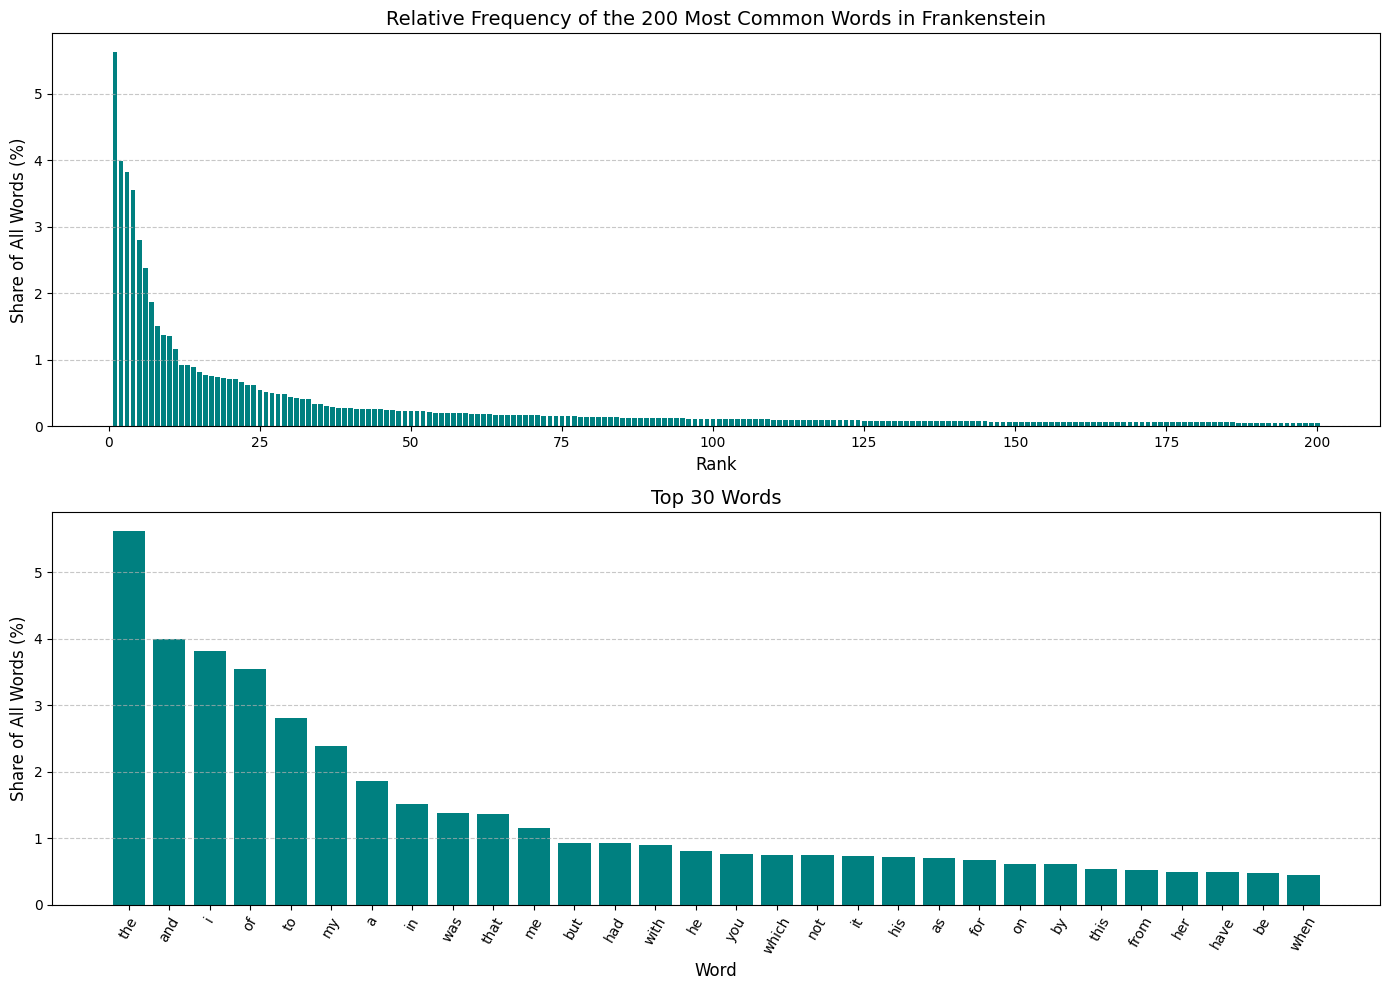

In [ ]:
# Relative frequency of the top 200 words:

# Quick print out for myself
print(top_200.loc[top_200["rank"].isin([1, 4, 25, 50, 100, 200]), ["rank", "word", "relative_frequency"]].to_string(index=False))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

ax1.bar(top_200["rank"], top_200["relative_frequency"] * 100, color="teal")
ax1.set_title("Relative Frequency of the 200 Most Common Words in Frankenstein", fontsize=14)
ax1.set_xlabel("Rank", fontsize=12)
ax1.set_ylabel("Share of All Words (%)", fontsize=12)
ax1.grid(axis="y", linestyle="--", alpha=0.7)

top_30 = top_200.head(30)
ax2.bar(top_30["word"], top_30["relative_frequency"] * 100, color="teal")
ax2.set_title("Top 30 Words", fontsize=14)
ax2.set_xlabel("Word", fontsize=12)
ax2.set_ylabel("Share of All Words (%)", fontsize=12)
ax2.tick_params(axis="x", rotation=60)
ax2.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

**Relative Frequency Summary**

* The bars drop off a pretty heavily after the first few words
  * "The" alone is ~5.6% of the book, and the top 4 words are each over 3.5%. By about rank 25 a word is down to ~0.5% of the book, and by rank 100 it's around 0.1%.
* After that, the bars flatten out into a long tail

## Question 6: Does It Follow Zipf's Law?

Zipf's law says that a word's frequency is inversely proportional to its rank: frequency × rank should stay about the same for every word. The book's example is that the 50th most common word should show up about three times as often as the 150th. On a log-log plot, a text that follows Zipf's law shows up as a straight line sloping down at about −1.

Slope of the log-log line (Zipf predicts about -1): -1.04
Rank 50 vs rank 150 frequency ratio (Zipf predicts 3): 3.33

Frequency x rank (Zipf predicts this stays roughly constant):
min     4185.0
25%     7956.0
50%     8167.0
75%     8489.0
max    11046.0


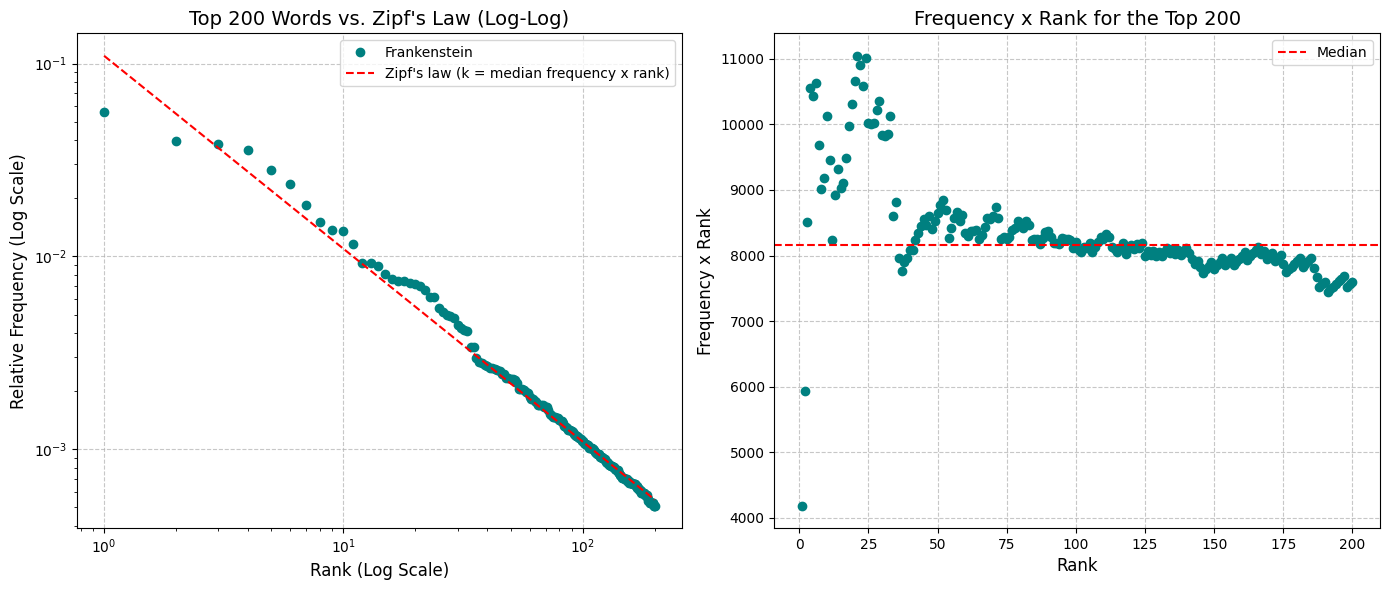

In [ ]:
# Compare the top 200 with what Zipf's law predicts
top_200["freq_x_rank"] = top_200["count"] * top_200["rank"]
# Zipf constant k: the typical (median) frequency x rank, so the reference line runs through the data
# rather than being pinned to "the", which sits below the trend
zipf_constant = top_200["freq_x_rank"].median()
zipf_prediction = (zipf_constant / total_words) / top_200["rank"]

slope, _ = np.polyfit(np.log10(top_200["rank"]), np.log10(top_200["relative_frequency"]), 1)
ratio_50_150 = top_200.loc[49, "count"] / top_200.loc[149, "count"]

print(f"Slope of the log-log line (Zipf predicts about -1): {slope:.2f}")
print(f"Rank 50 vs rank 150 frequency ratio (Zipf predicts 3): {ratio_50_150:.2f}")
print("\nFrequency x rank (Zipf predicts this stays roughly constant):")
print(top_200["freq_x_rank"].describe()[["min", "25%", "50%", "75%", "max"]].round(0).to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.loglog(top_200["rank"], top_200["relative_frequency"], marker="o", linestyle="none", color="teal", label="Frankenstein")
ax1.loglog(top_200["rank"], zipf_prediction, color="red", linestyle="--", label="Zipf's law (k = median frequency x rank)")
ax1.set_title("Top 200 Words vs. Zipf's Law (Log-Log)", fontsize=14)
ax1.set_xlabel("Rank (Log Scale)", fontsize=12)
ax1.set_ylabel("Relative Frequency (Log Scale)", fontsize=12)
ax1.legend()
ax1.grid(linestyle="--", alpha=0.7)

ax2.plot(top_200["rank"], top_200["freq_x_rank"], marker="o", linestyle="none", color="teal")
ax2.axhline(top_200["freq_x_rank"].median(), color="red", linestyle="--", label="Median")
ax2.set_title("Frequency x Rank for the Top 200", fontsize=14)
ax2.set_xlabel("Rank", fontsize=12)
ax2.set_ylabel("Frequency x Rank", fontsize=12)
ax2.legend()
ax2.grid(linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

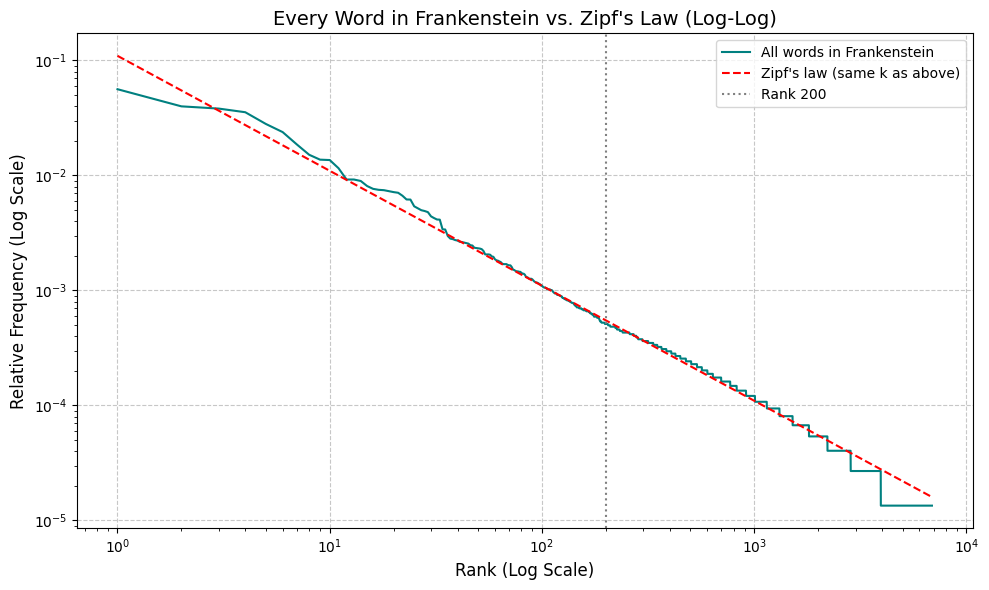

In [ ]:
# The whole vocabulary on a log-log plot, to see what happens at the extreme ends
all_ranks = np.arange(1, unique_words + 1)
all_freqs = counts / total_words

plt.figure(figsize=(10, 6))
plt.loglog(all_ranks, all_freqs, color="teal", label="All words in Frankenstein")
plt.loglog(all_ranks, (zipf_constant / total_words) / all_ranks, color="red", linestyle="--", label="Zipf's law (same k as above)")
plt.axvline(200, color="gray", linestyle=":", label="Rank 200")
plt.title("Every Word in Frankenstein vs. Zipf's Law (Log-Log)", fontsize=14)
plt.xlabel("Rank (Log Scale)", fontsize=12)
plt.ylabel("Relative Frequency (Log Scale)", fontsize=12)
plt.legend()
plt.grid(linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

**Zipf's Law Summary**

* Yes, the top 200 words follow Zipf's law very closely
  * The log-log line has a slope of −1.04, right next to the −1 that Zipf predicts. The book's own check works too: the 50th most common word shows up ~3.3 times as often as the 150th, close to the predicted 3.
* Frequency × rank stays almost flat for most of the list
  * Zipf's law says a word's count times its rank should come out about the same for every word. For half of the top 200 words, that number lands between ~8.0K and ~8.5K, and after about rank 35 the points stay close to the red line in the right-hand plot.
* This pattern does break down at the extreme ends
  * So at the very top, "the" and "and" show up less often than Zipf predict, and the next few dozen words show up a bit more often too.
  * At the very bottom of the full vocabulary, the line turns into steps, because lots of words share the exact same small count. The last and longest step is the ~2.9K words that are used only once, and it sits below the Zipf line, since a word can't show up less than once.

## Question 7: How Is Frankenstein Different From "All Words in All Corpora"?

There's no way to count every word in every corpus, so I use the Brown Corpus to compare. The book describes it as the first million-word collection of English, drawn from many kinds of writing (news, fiction, government documents, and more). I cleaned it the same way as Frankenstein (lowercased, letters only) and  compared.

In [ ]:
# Build the same kind of frequency distribution for the Brown Corpus
brown_words = [w.lower() for w in brown.words() if w.isalpha()]
brown_fdist = nltk.FreqDist(brown_words)
brown_total = brown_fdist.N()
brown_rank = {w: r for r, (w, _) in enumerate(brown_fdist.most_common(), start=1)}
brown_top_200 = {w for w, _ in brown_fdist.most_common(200)}

print(f"Brown Corpus: {brown_total:,} words, {brown_fdist.B():,} unique words")

top_words = set(top_200["word"])
shared = top_words & brown_top_200
print(f"{len(shared)} of Frankenstein's top 200 words are also in Brown's top 200.")

english_stopwords = set(stopwords.words("english"))
print(
    f"Stopwords in the top 200: Frankenstein {sum(w in english_stopwords for w in top_200['word'])},"
    f" Brown {sum(w in english_stopwords for w in brown_top_200)}"
)

Brown Corpus: 981,716 words, 40,234 unique words
133 of Frankenstein's top 200 words are also in Brown's top 200.
Stopwords in the top 200: Frankenstein 93, Brown 104


In [ ]:
# Which top-200 words does Frankenstein use far more (or less) than general English?
comparison = top_200[["rank", "word", "relative_frequency"]].copy()
comparison["brown_rank"] = comparison["word"].map(brown_rank)
comparison["brown_relative_frequency"] = comparison["word"].map(lambda w: brown_fdist[w] / brown_total)
comparison["times_more_than_brown"] = (
    comparison["relative_frequency"] / comparison["brown_relative_frequency"]
).replace(np.inf, np.nan)

not_in_brown = comparison.loc[comparison["brown_rank"].isna(), "word"].tolist()
print(f"Top-200 words that never appear in Brown: {', '.join(not_in_brown) if not_in_brown else 'none'}\n")

print("--- Top-200 words Frankenstein uses most heavily compared with Brown ---")
print(
    comparison.dropna(subset=["times_more_than_brown"])
    .sort_values("times_more_than_brown", ascending=False)
    .head(20)
    .round(4)
    .to_string(index=False)
)

missing = sorted((brown_rank[w], w) for w in brown_top_200 if w not in top_words)
print(f"\n--- Brown's top 200 words that are NOT in Frankenstein's top 200 ({len(missing)} words) ---")
print(f"(Of Brown's top 50, {sum(r <= 50 for r, _ in missing)} are missing from Frankenstein's top 200.)")
print(textwrap.fill(", ".join(f"{r}. {w}" for r, w in missing), width=110) if missing else "None")

Top-200 words that never appear in Brown: clerval

--- Top-200 words Frankenstein uses most heavily compared with Brown ---
 rank      word  relative_frequency  brown_rank  brown_relative_frequency  times_more_than_brown
  144   justine              0.0007     28909.0                    0.0000               725.5554
   92 elizabeth              0.0012      5900.0                    0.0000                78.2720
  126 miserable              0.0009      6508.0                    0.0000                64.9448
  148    misery              0.0007      5966.0                    0.0000                46.6114
  180  creature              0.0006      5846.0                    0.0000                38.6963
  156   cottage              0.0007      4865.0                    0.0000                35.4099
  185    horror              0.0006      5406.0                    0.0000                33.3678
  165   despair              0.0007      4489.0                    0.0000                30.7811
  1

In [ ]:
# What kinds of words are in the top 200?
tagged = nltk.pos_tag(tokens)
tags_by_word = {}
for token, tag in tagged:
  word = token.lower()
  if word in top_words:
    tags_by_word.setdefault(word, Counter())[tag] += 1


def word_type(tag):
  """Group Penn Treebank tags into broad word types."""
  if tag.startswith("PRP") or tag.startswith("WP"):
    return "Pronoun"
  if tag.startswith("NN"):
    return "Noun"
  if tag.startswith("VB") or tag == "MD":
    return "Verb"
  if tag.startswith("JJ"):
    return "Adjective"
  if tag.startswith("RB") or tag == "WRB":
    return "Adverb"
  if tag in ("DT", "PDT", "WDT"):
    return "Determiner"
  if tag in ("IN", "TO"):
    return "Preposition"
  if tag == "CC":
    return "Conjunction"
  return "Other"


top_200["word_type"] = top_200["word"].map(lambda w: word_type(tags_by_word[w].most_common(1)[0][0]))
print(top_200["word_type"].value_counts().to_string())
print("\nNouns in the top 200:", ", ".join(top_200.loc[top_200["word_type"] == "Noun", "word"]))

word_type
Noun           48
Verb           37
Adverb         27
Preposition    26
Pronoun        23
Adjective      18
Determiner     13
Other           5
Conjunction     3

Nouns in the top 200: man, father, life, eyes, time, towards, elizabeth, night, mind, day, heart, feelings, death, friend, love, place, clerval, justine, misery, friends, country, nature, words, cottage, hope, happiness, despair, felix, days, voice, sun, world, years, men, creature, scene, horror, light, fear, joy, affection, part, months, nothing, ice, morning, power, thoughts


**Frankenstein vs. General English Summary**

* Frankenstein and general English share most of their most common words
  * 133 of Frankenstein's top 200 words are also in Brown's top 200, and every one of Brown's top 50 words is somewhere in Frankenstein's top 200. Many of these shared words are ‘plumbing’ words: 93 of Frankenstein’s top 200 are on NLTK’s stopword list, compared with 104 for Brown.
* The biggest differences are the characters, the narration, and the emotions
  * Character names are a lot more common than in general English: "Justine" shows up ~700 times as often as in Brown, "Elizabeth" ~80 times, and "Clerval" never appears in Brown.
  * There are a lot of emotional words in Frankenstein. There's "miserable" ~65 times as often as in Brown, "misery" ~45 times, and "horror," "despair," "affection," "happiness," "feelings" and "joy" 10–35 times.
  * The first person shows up again too: "my" ~18 times as often, "myself" ~14 times and "me" ~10 times.
  * AA few words probably just reflect older or more formal writing, like "towards" (~19 times as often as in Brown).
* The common Brown words that Frankenstein is missing are mostly about modern public life and everyday talk
  * 67 of Brown's top 200 words aren't in Frankenstein's top 200. Many come from the news, government and school writing in Brown ("American," "United," "States," "school," "war," "public," "people," "work"). Others are casual, everyday words ("get," "got," "go," "just," "back," "think," "something").  
* The word types show the same split between "plumbing" words and story words
  * Of the top 200, ~50 are nouns, ~35 verbs and ~25 each adverbs, prepositions and pronouns.
  * Side note: the tagger isn't perfect. It calls "towards" a noun, which it isn't.

## Final Responses

**1. Choose a corpus of interest.**

* Mary Shelley's *Frankenstein*, read straight from Project Gutenberg. After cleaning, it has ~74K words.

**2. How many total unique words are in the corpus?**

* ~6.9K unique words, counting lowercased words made only of letters.  

**3. Taking the most common words, how many unique words represent half of the total words in the corpus?**

* 60 words, which is less than 1% of the vocabulary.

**4. Identify the 200 highest frequency words in this corpus.**

* They're listed in Question 4. Together they make up ~63% of the book. The top of the list is mostly "plumbing" words like "the," "and" and "of," with "I," "my" and "me" ranked unusually high.

**5. Create a graph that shows the relative frequency of these 200 words.**

* The bar charts in Question 5 show it: the bars drop off pretty steeply after the first few words, then flatten into a long tail.

**6. Does the observed relative frequency of these words follow Zipf's law? Explain.**

* Yes, very closely, which is what I expected. The log-log slope is −1.04 (Zipf predicts −1), the 50th word shows up ~3.3 times as often as the 150th (Zipf predicts 3), and frequency × rank stays nearly flat. It only bends at the extreme ends: the very top few words, and the ~2.9K words used only once.

**7. In what ways do you think the frequency of the words in this corpus differ from "all words in all corpora."**

* Compared with the Brown Corpus, Frankenstein uses the same plumbing words, but far more character names (Elizabeth, Justine, Clerval), first-person words ("my" ~18 times as often) and emotional words ("misery," "despair," "horror"). Words that seem to refer to American culture and lifestyle don't show up in Frankenstein whereas they do in the Brown Corpus; words like "American," "school" and "war".
